بررسی ساختار دیتاست 


In [11]:
from huggingface_hub import HfApi
from huggingface_hub.hf_api import RepoFile, RepoFolder
from collections import Counter
from pathlib import PurePosixPath
import pandas as pd

# ==========================================
# 1. Dataset Configuration
# ==========================================

REPO_ID = "nexar-ai/nexar_collision_prediction"

api = HfApi()

# ==========================================
# 2. Get Repository Structure
# ==========================================

print("Fetching dataset structure...")

items = list(api.list_repo_tree(
    repo_id=REPO_ID,
    repo_type="dataset",
    recursive=True
))

# Separate files and folders
repo_files = [
    f for f in items
    if isinstance(f, RepoFile)
]

repo_folders = [
    f for f in items
    if isinstance(f, RepoFolder)
]

print("\n========== DATASET INFORMATION ==========")

print("Repository:", REPO_ID)
print("Total files:", len(repo_files))
print("Total folders:", len(repo_folders))

# ==========================================
# 3. Folder Structure
# ==========================================

print("\n========== FOLDER STRUCTURE ==========")

for folder in sorted(repo_folders, key=lambda x: x.path):
    depth = folder.path.count("/")

    if depth <= 2:
        print("  " * depth + folder.path)

# ==========================================
# 4. File Format Distribution
# ==========================================

extensions = Counter(
    PurePosixPath(f.path).suffix.lower()
    for f in repo_files
)

print("\n========== FILE FORMATS ==========")

for ext, count in sorted(extensions.items()):
    print(f"{ext or '[no extension]'}: {count}")

# ==========================================
# 5. Create File Inventory
# ==========================================

inventory = pd.DataFrame([
    {
        "path": f.path,
        "type": "file",
        "extension": PurePosixPath(f.path).suffix.lower(),
        "size_mb": (
            round(f.size / (1024**2), 2)
            if f.size is not None else None
        )
    }
    for f in repo_files
])

print("\n========== FILE INVENTORY ==========")

display(inventory.head(20))

# ==========================================
# 6. Video Distribution
# ==========================================

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}

videos = inventory[
    inventory["extension"].isin(video_extensions)
].copy()

videos["folder"] = videos["path"].apply(
    lambda x: str(PurePosixPath(x).parent)
)

print("\n========== VIDEO DISTRIBUTION ==========")

video_distribution = (
    videos.groupby("folder")
    .size()
    .reset_index(name="video_count")
)

display(video_distribution)

print("Total videos:", len(videos))

# ==========================================
# 7. Dataset Size
# ==========================================

print("\n========== DATASET SIZE ==========")

total_size_gb = inventory["size_mb"].sum() / 1024
video_size_gb = videos["size_mb"].sum() / 1024

print(f"Total dataset size: {total_size_gb:.2f} GB")
print(f"Total video size: {video_size_gb:.2f} GB")

unknown_sizes = inventory["size_mb"].isna().sum()

if unknown_sizes:
    print(f"Warning: {unknown_sizes} files have unknown sizes.")

# ==========================================
# 8. Metadata Files
# ==========================================

print("\n========== METADATA FILES ==========")

metadata_files = inventory[
    inventory["path"].str.contains(
        r"metadata|\.csv$",
        case=False,
        regex=True
    )
]

display(metadata_files)

# ==========================================
# 9. Sample Video Files
# ==========================================

print("\n========== SAMPLE VIDEOS ==========")

display(
    videos[["path", "size_mb", "folder"]].head(10)
)

# ==========================================
# 10. Summary
# ==========================================

print("\n========== FINAL SUMMARY ==========")

print("Total files:", len(repo_files))
print("Total folders:", len(repo_folders))
print("Total videos:", len(videos))
print("Metadata/CSV files:", len(metadata_files))
print("Dataset size (GB):", round(total_size_gb, 2))

print("\n========== INSPECTION COMPLETED ==========")

Fetching dataset structure...

========== DATASET INFORMATION ==========
Repository: nexar-ai/nexar_collision_prediction
Total files: 2857
Total folders: 9

========== FOLDER STRUCTURE ==========
test-private
  test-private/negative
  test-private/positive
test-public
  test-public/negative
  test-public/positive
train
  train/negative
  train/positive

========== FILE FORMATS ==========
[no extension]: 2
.csv: 9
.md: 1
.mp4: 2844
.py: 1

========== FILE INVENTORY ==========


,path,type,extension,size_mb
0,.gitattributes,file,,0.00
1,LICENSE,file,,0.00
2,README.md,file,.md,0.00
3,evaluate_submission.py,file,.py,0.00
4,sample_submission.csv,file,.csv,0.03
5,solution.csv,file,.csv,0.02
6,test-private/negative/01047.mp4,file,.mp4,2.60
7,test-private/negative/01053.mp4,file,.mp4,4.79
8,test-private/negative/01055.mp4,file,.mp4,5.33
9,test-private/negative/01057.mp4,file,.mp4,5.33



========== VIDEO DISTRIBUTION ==========


,folder,video_count
0,test-private/negative,339
1,test-private/positive,338
2,test-public/negative,333
3,test-public/positive,334
4,train/negative,750
5,train/positive,750


Total videos: 2844

========== DATASET SIZE ==========
Total dataset size: 29.22 GB
Total video size: 29.22 GB

========== METADATA FILES ==========


,path,type,extension,size_mb
4,sample_submission.csv,file,.csv,0.03
5,solution.csv,file,.csv,0.02
345,test-private/negative/metadata.csv,file,.csv,0.01
684,test-private/positive/metadata.csv,file,.csv,0.02
1018,test-public/negative/metadata.csv,file,.csv,0.01
1353,test-public/positive/metadata.csv,file,.csv,0.02
1354,time_to_accident_test_map.csv,file,.csv,0.01
2105,train/negative/metadata.csv,file,.csv,0.02
2856,train/positive/metadata.csv,file,.csv,0.03



========== SAMPLE VIDEOS ==========


,path,size_mb,folder
6,test-private/negative/01047.mp4,2.60,test-private/negative
7,test-private/negative/01053.mp4,4.79,test-private/negative
8,test-private/negative/01055.mp4,5.33,test-private/negative
9,test-private/negative/01057.mp4,5.33,test-private/negative
10,test-private/negative/01063.mp4,5.29,test-private/negative
11,test-private/negative/01064.mp4,3.31,test-private/negative
12,test-private/negative/01077.mp4,2.36,test-private/negative
13,test-private/negative/01082.mp4,3.30,test-private/negative
14,test-private/negative/01086.mp4,2.89,test-private/negative
15,test-private/negative/01087.mp4,2.20,test-private/negative



========== FINAL SUMMARY ==========
Total files: 2857
Total folders: 9
Total videos: 2844
Metadata/CSV files: 9
Dataset size (GB): 29.22

========== INSPECTION COMPLETED ==========


دریافت متادیتا 

In [12]:
from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path
import pandas as pd

# 1. Configuration
REPO_ID = "nexar-ai/nexar_collision_prediction"
SAVE_DIR = Path("data/metadata")

SAVE_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi()

# 2. Find metadata files
repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

metadata_files = [
    path for path in repo_files
    if Path(path).name.lower() == "metadata.csv"
]

print("Metadata files found:", len(metadata_files))
print(*metadata_files, sep="\n")

# 3. Download and read metadata
metadata_dfs = {}

for file_path in metadata_files:

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=file_path,
        local_dir=SAVE_DIR
    )

    df = pd.read_csv(local_path)
    metadata_dfs[file_path] = df

    print(f"\n========== {file_path} ==========")

    print("Shape:", df.shape)
    print("\nColumns:", df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nFirst 5 Rows:")
    display(df.head())

print("\nMetadata download completed!")
print("Saved in:", SAVE_DIR.resolve())

Metadata files found: 6
test-private/negative/metadata.csv
test-private/positive/metadata.csv
test-public/negative/metadata.csv
test-public/positive/metadata.csv
train/negative/metadata.csv
train/positive/metadata.csv

========== test-private/negative/metadata.csv ==========
Shape: (339, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event       339
time_of_alert       339
light_conditions      0
weather               0
scene                 0
time_to_accident      0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01047.mp4,NaN,NaN,Normal,Clear,Urban,0.5
1,01053.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
2,01055.mp4,NaN,NaN,Normal,Cloudy,Highway,0.5
3,01057.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
4,01063.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5



========== test-private/positive/metadata.csv ==========
Shape: (338, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name           0
time_of_event       0
time_of_alert       0
light_conditions    0
weather             0
scene               0
time_to_accident    0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,00001.mp4,19.967,18.067,Normal,Clear,Highway,0.5
1,00011.mp4,20.867,19.367,Normal,Clear,Highway,0.5
2,00012.mp4,18.722,18.461,Normal,Clear,Urban,0.5
3,00033.mp4,18.933,16.000,Normal,Clear,Highway,0.5
4,00034.mp4,20.067,18.633,Normal,Clear,Urban,0.5



========== test-public/negative/metadata.csv ==========
Shape: (333, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event       333
time_of_alert       333
light_conditions      0
weather               0
scene                 0
time_to_accident      0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01044.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
1,01056.mp4,NaN,NaN,Normal,Clear,Urban,0.5
2,01059.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
3,01065.mp4,NaN,NaN,Normal,Clear,Sub-urban,0.5
4,01068.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5


... (3 outputs left out)

,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01924.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN
1,01429.mp4,NaN,NaN,Normal,Rain,Urban,NaN
2,01904.mp4,NaN,NaN,Normal,Cloudy,Urban,NaN
3,01486.mp4,NaN,NaN,Normal,Clear,Urban,NaN
4,01171.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN



========== train/positive/metadata.csv ==========
Shape: (750, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event         0
time_of_alert         0
light_conditions      0
weather               1
scene                 0
time_to_accident    750
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,00822.mp4,19.500,18.633,Normal,Cloudy,Urban,NaN
1,00208.mp4,19.800,19.233,Normal,Cloudy,Sub-urban,NaN
2,00072.mp4,20.101,20.068,Normal,Clear,Urban,NaN
3,00128.mp4,19.267,18.333,Normal,Clear,Urban,NaN
4,00205.mp4,21.146,18.196,Normal,Clear,Highway,NaN



Metadata download completed!
Saved in: C:\Users\Mobin-pc\Desktop\AI Bootcamp\Week 11 (Project2)\Github Clone\DL-Project\image_neural_network\data\metadata


جلوگیری از نشت دیتا ، شماره 1 


In [13]:
import pandas as pd

# Columns that may cause Data Leakage
leakage_columns = [
    "time_of_event",
    "time_of_alert",
    "time_to_accident"
]

prepared_metadata = {}

for file_path, original_df in metadata_dfs.items():

    # Keep original data unchanged
    df = original_df.copy()

    # Create binary labels
    df["label"] = df["time_of_event"].notna().astype(int)

    # Remove leakage columns
    df = df.drop(columns=leakage_columns)

    # Store processed metadata
    prepared_metadata[file_path] = df

    print(f"\n{file_path}")
    print("Shape:", df.shape)
    print("Labels:", df["label"].value_counts().to_dict())

# Check final structure
print("\n========== FINAL COLUMNS ==========")
display(prepared_metadata["train/positive/metadata.csv"].head())

# Verify removed columns
for df in prepared_metadata.values():
    assert not any(col in df.columns for col in leakage_columns)

print("\nData Leakage columns removed successfully!- S1")


test-private/negative/metadata.csv
Shape: (339, 5)
Labels: {0: 339}

test-private/positive/metadata.csv
Shape: (338, 5)
Labels: {1: 338}

test-public/negative/metadata.csv
Shape: (333, 5)
Labels: {0: 333}

test-public/positive/metadata.csv
Shape: (334, 5)
Labels: {1: 334}

train/negative/metadata.csv
Shape: (750, 5)
Labels: {0: 750}

train/positive/metadata.csv
Shape: (750, 5)
Labels: {1: 750}

========== FINAL COLUMNS ==========


,file_name,light_conditions,weather,scene,label
0,00822.mp4,Normal,Cloudy,Urban,1
1,00208.mp4,Normal,Cloudy,Sub-urban,1
2,00072.mp4,Normal,Clear,Urban,1
3,00128.mp4,Normal,Clear,Urban,1
4,00205.mp4,Normal,Clear,Highway,1



Data Leakage columns removed successfully!- S1


بررسی کیفیت و سلامت ویدئوها و شناسایی فایل‌های تکراری.

========== METADATA LEAKAGE AUDIT ==========

Probability of Accident (Label=1) given light_conditions:
light_conditions
Bright      0.700000
Normal      0.501845
Dark        0.468085
Twilight    0.465909
Name: label, dtype: float64

Probability of Accident (Label=1) given weather:
weather
Snow      1.000000
Rain      0.722892
Cloudy    0.490909
Clear     0.484222
Name: label, dtype: float64

Probability of Accident (Label=1) given scene:
scene
Nature        1.000000
Other         0.647059
Urban         0.605867
Highway       0.451187
Sub-urban     0.276753
Industrial    0.230769
Rural         0.166667
Name: label, dtype: float64


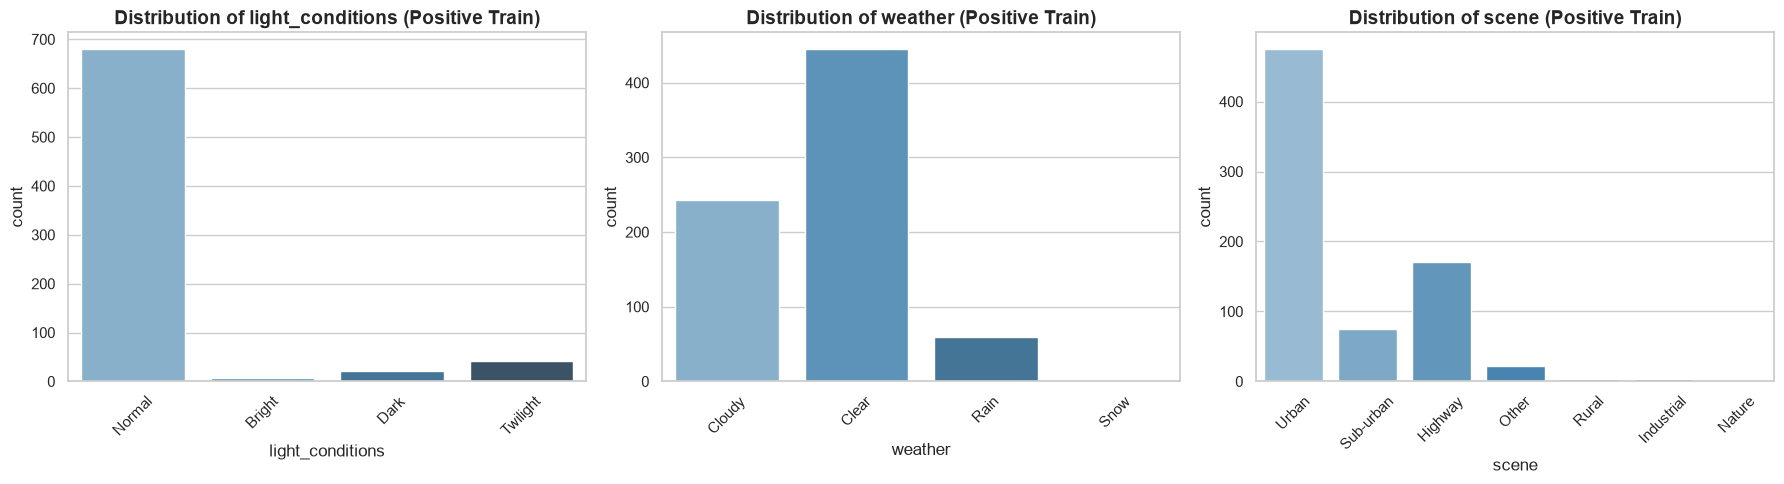

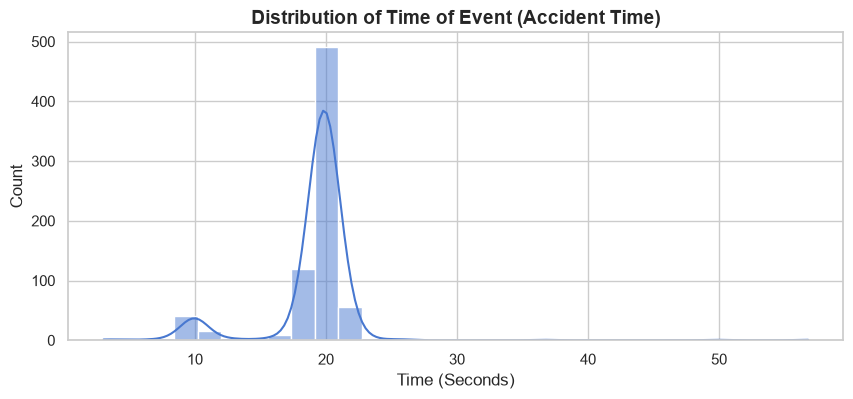

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine positive and negative for leakage audit
df_pos = prepared_metadata['train/positive/metadata.csv']
df_neg = prepared_metadata['train/negative/metadata.csv']
df_all_train = pd.concat([df_pos, df_neg])

# --- 1. METADATA LEAKAGE AUDIT ---
print("========== METADATA LEAKAGE AUDIT ==========")
for col in ['light_conditions', 'weather', 'scene']:
    leakage_check = df_all_train.groupby(col)['label'].mean().sort_values(ascending=False)
    print(f"\nProbability of Accident (Label=1) given {col}:")
    print(leakage_check)

# --- 2. DISTRIBUTION PLOTS (Fixed Warnings) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    sns.countplot(data=df_pos, x=col, ax=axes[i], hue=col, palette="Blues_d", legend=False)
    axes[i].set_title(f'Distribution of {col} (Positive Train)')
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# --- 3. TIME OF EVENT PLOT ---
plt.figure(figsize=(10, 4))
sns.histplot(data=metadata_dfs['train/positive/metadata.csv'], x='time_of_event', bins=30, kde=True)
plt.title('Distribution of Time of Event (Accident Time)')
plt.xlabel('Time (Seconds)')
plt.show()

نمونه‌گیری

In [15]:
import numpy as np
import pandas as pd
from pathlib import Path

# ==========================================
# 1. Configuration
# ==========================================
SEED = 42
INPUT_DIR = Path("data/processed_v2")
OUTPUT_DIR = Path("data/processed_v3")
CACHE_DIR = Path("data/video_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ENV_COLS = ["light_conditions", "weather", "scene"]

# 300 total = 150 per class | Train 240 = 120+120 | Val 60 = 30+30
N_PER_CLASS = 150
N_VAL_PER_CLASS = 30

# ==========================================
# 2. Load the 450 already-downloaded videos
# ==========================================
pool = pd.read_csv(INPUT_DIR / "sample_450.csv", dtype={"file_name": str})

assert len(pool) == 450, f"Expected 450 rows, got {len(pool)}"
assert pool["video_path"].is_unique

# Check that the files really exist in your local cache
missing = [p for p in pool["video_path"] if not (CACHE_DIR / p).exists()]
print("Videos in pool:", len(pool))
print("Missing from cache:", len(missing))
if missing:
    print("First missing:", missing[:5])
    print("Fix the cache path (CACHE_DIR) before continuing.")

positive = pool[pool["label"] == 1].copy()
negative = pool[pool["label"] == 0].copy()
print("Pool label counts:", pool["label"].value_counts().sort_index().to_dict())

# ==========================================
# 3. Representative Stratified Sampling
# ==========================================
def proportional_sample(frame, n, seed):
    if n > len(frame):
        raise ValueError("Sample size exceeds available data")

    working = frame.copy()
    working["_stratum"] = (
        working[ENV_COLS]
        .fillna("Missing")
        .astype(str)
        .agg(" | ".join, axis=1)
    )

    sizes = working["_stratum"].value_counts().sort_index()
    quotas = sizes * n / len(working)
    allocated = np.floor(quotas).astype(int)

    remaining = n - int(allocated.sum())
    if remaining > 0:
        fractions = (quotas - allocated).sort_values(
            ascending=False, kind="stable"
        )
        allocated.loc[fractions.index[:remaining]] += 1

    rng = np.random.default_rng(seed)
    selected = []
    groups = working.groupby("_stratum", sort=True)

    for group, count in allocated.items():
        if count > 0:
            part = groups.get_group(group).sample(
                n=int(count),
                random_state=int(rng.integers(0, 2**32 - 1))
            )
            selected.append(part)

    result = pd.concat(selected, ignore_index=True)
    return (
        result.drop(columns="_stratum")
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

# ==========================================
# 4. Select 300 of the 450 (150 + 150)
# ==========================================
sample_positive = proportional_sample(positive, n=N_PER_CLASS, seed=SEED)
sample_negative = proportional_sample(negative, n=N_PER_CLASS, seed=SEED + 1)

sample_300 = pd.concat(
    [sample_positive, sample_negative], ignore_index=True
).sample(frac=1, random_state=SEED).reset_index(drop=True)

print("\n========== 300 SELECTED ==========")
print(sample_300["label"].value_counts().sort_index())

# ==========================================
# 5. Validation Split (30 + 30 = 60)
# ==========================================
val_positive = proportional_sample(sample_positive, n=N_VAL_PER_CLASS, seed=SEED + 2)
val_negative = proportional_sample(sample_negative, n=N_VAL_PER_CLASS, seed=SEED + 3)

final_val = pd.concat(
    [val_positive, val_negative], ignore_index=True
).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Remaining 240 become Train
final_train = sample_300[
    ~sample_300["video_path"].isin(final_val["video_path"])
].copy().reset_index(drop=True)

# ==========================================
# 6. Leakage & Size Checks
# ==========================================
assert set(final_train["video_path"]).isdisjoint(set(final_val["video_path"]))
assert set(final_train["file_name"]).isdisjoint(set(final_val["file_name"]))
assert len(sample_300) == 300
assert len(final_train) == 240
assert len(final_val) == 60
assert final_train["label"].value_counts().to_dict() == {0: 120, 1: 120}
assert final_val["label"].value_counts().to_dict() == {0: 30, 1: 30}
print("\nData leakage checks passed!")

# ==========================================
# 7. Save
# ==========================================
final_train.to_csv(OUTPUT_DIR / "train_240.csv", index=False)
final_val.to_csv(OUTPUT_DIR / "val_60.csv", index=False)
sample_300.to_csv(OUTPUT_DIR / "sample_300.csv", index=False)

print("Saved in:", OUTPUT_DIR.resolve())
print("Train:", len(final_train), final_train["label"].value_counts().to_dict())
print("Val:  ", len(final_val), final_val["label"].value_counts().to_dict())


Videos in pool: 450
Missing from cache: 0
Pool label counts: {0: 225, 1: 225}

========== 300 SELECTED ==========
label
0    150
1    150
Name: count, dtype: int64

Data leakage checks passed!
Saved in: C:\Users\Mobin-pc\Desktop\AI Bootcamp\Week 11 (Project2)\Github Clone\DL-Project\image_neural_network\data\processed_v3
Train: 240 {0: 120, 1: 120}
Val:   60 {1: 30, 0: 30}


ذخیره‌سازی

In [16]:
import os

# 1. Save Train and Validation sets
os.makedirs("data/processed", exist_ok=True)

final_train.to_csv("data/processed/final_train.csv", index=False)
final_val.to_csv("data/processed/final_val.csv", index=False)

print("✅ Saved final_train.csv and final_val.csv")

# 2. Prepare the Test Sets (Public and Private)
test_frames = []

for split in ['test-public', 'test-private']:
    for label_type in ['positive', 'negative']:
        path = f'{split}/{label_type}/metadata.csv'
        if path in prepared_metadata:
            df = prepared_metadata[path].copy()
            # Add subset and absolute video path
            df['subset'] = split
            df['video_path'] = f'{split}/{label_type}/' + df['file_name']
            test_frames.append(df)

final_test = pd.concat(test_frames).reset_index(drop=True)

# Save Test set
final_test.to_csv("data/processed/final_test.csv", index=False)
print("✅ Saved final_test.csv")

# 3. Final Sanity Check
print("\n========== FINAL DATASET SHAPES ==========")
print(f"Train: {final_train.shape} | Labels: {final_train['label'].value_counts().to_dict()}")
print(f"Val:   {final_val.shape} | Labels: {final_val['label'].value_counts().to_dict()}")
print(f"Test:  {final_test.shape} | Labels: {final_test['label'].value_counts().to_dict()}")

print("\n========== FINAL COLUMNS ==========")
print(list(final_train.columns))

✅ Saved final_train.csv and final_val.csv
✅ Saved final_test.csv

========== FINAL DATASET SHAPES ==========
Train: (240, 9) | Labels: {0: 120, 1: 120}
Val:   (60, 9) | Labels: {1: 30, 0: 30}
Test:  (1344, 7) | Labels: {1: 672, 0: 672}

========== FINAL COLUMNS ==========
['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident', 'label', 'video_path']


مصورسازی داده‌ها (Data Visualization)

========== CLASS BALANCE ACROSS SPLITS ==========


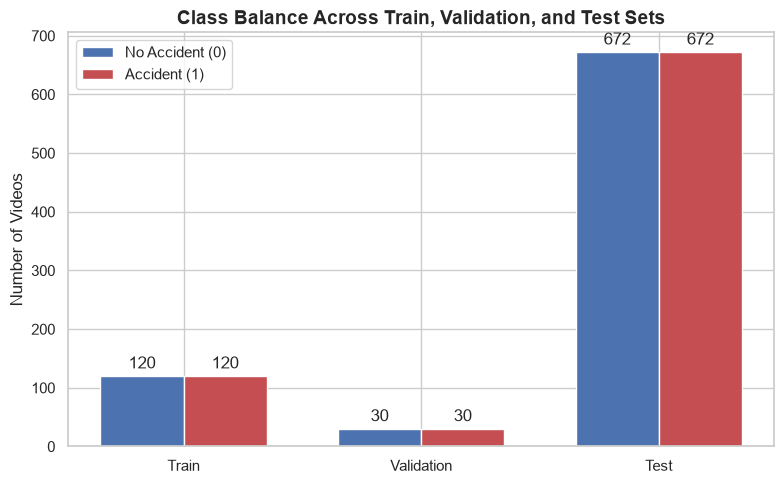


========== METADATA LEAKAGE AUDIT ==========


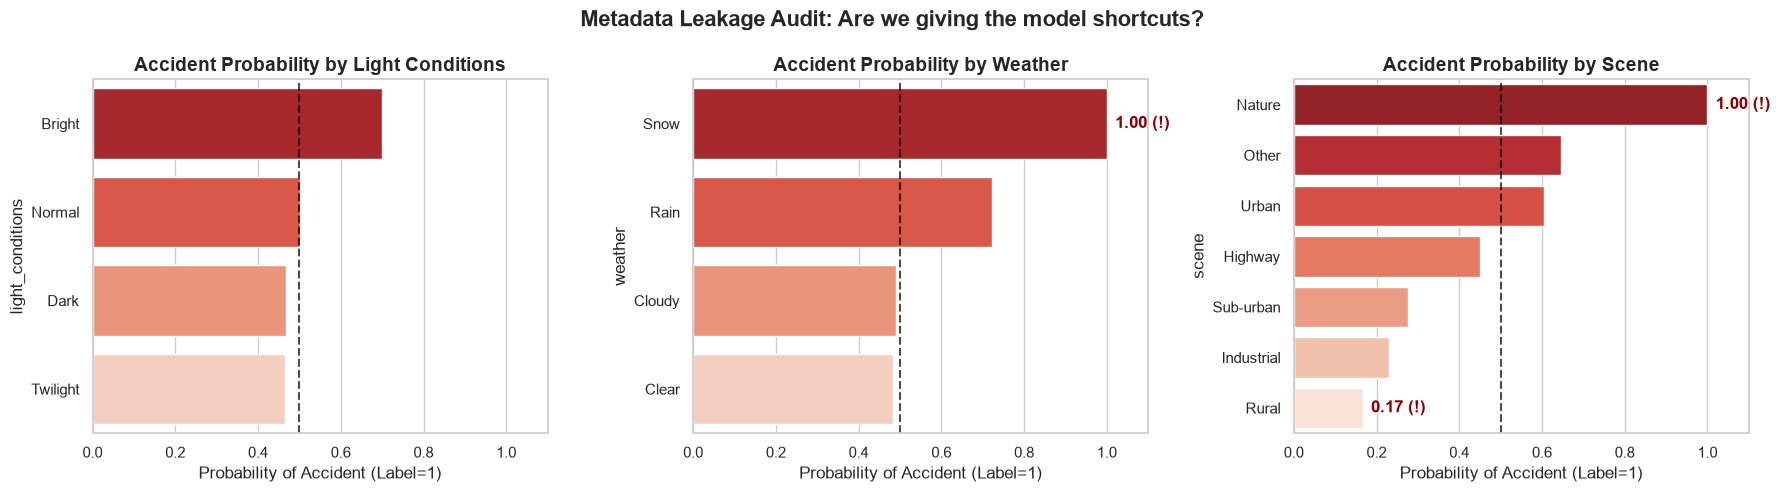


========== POSITIVE VS NEGATIVE ENVIRONMENT DISTRIBUTIONS ==========


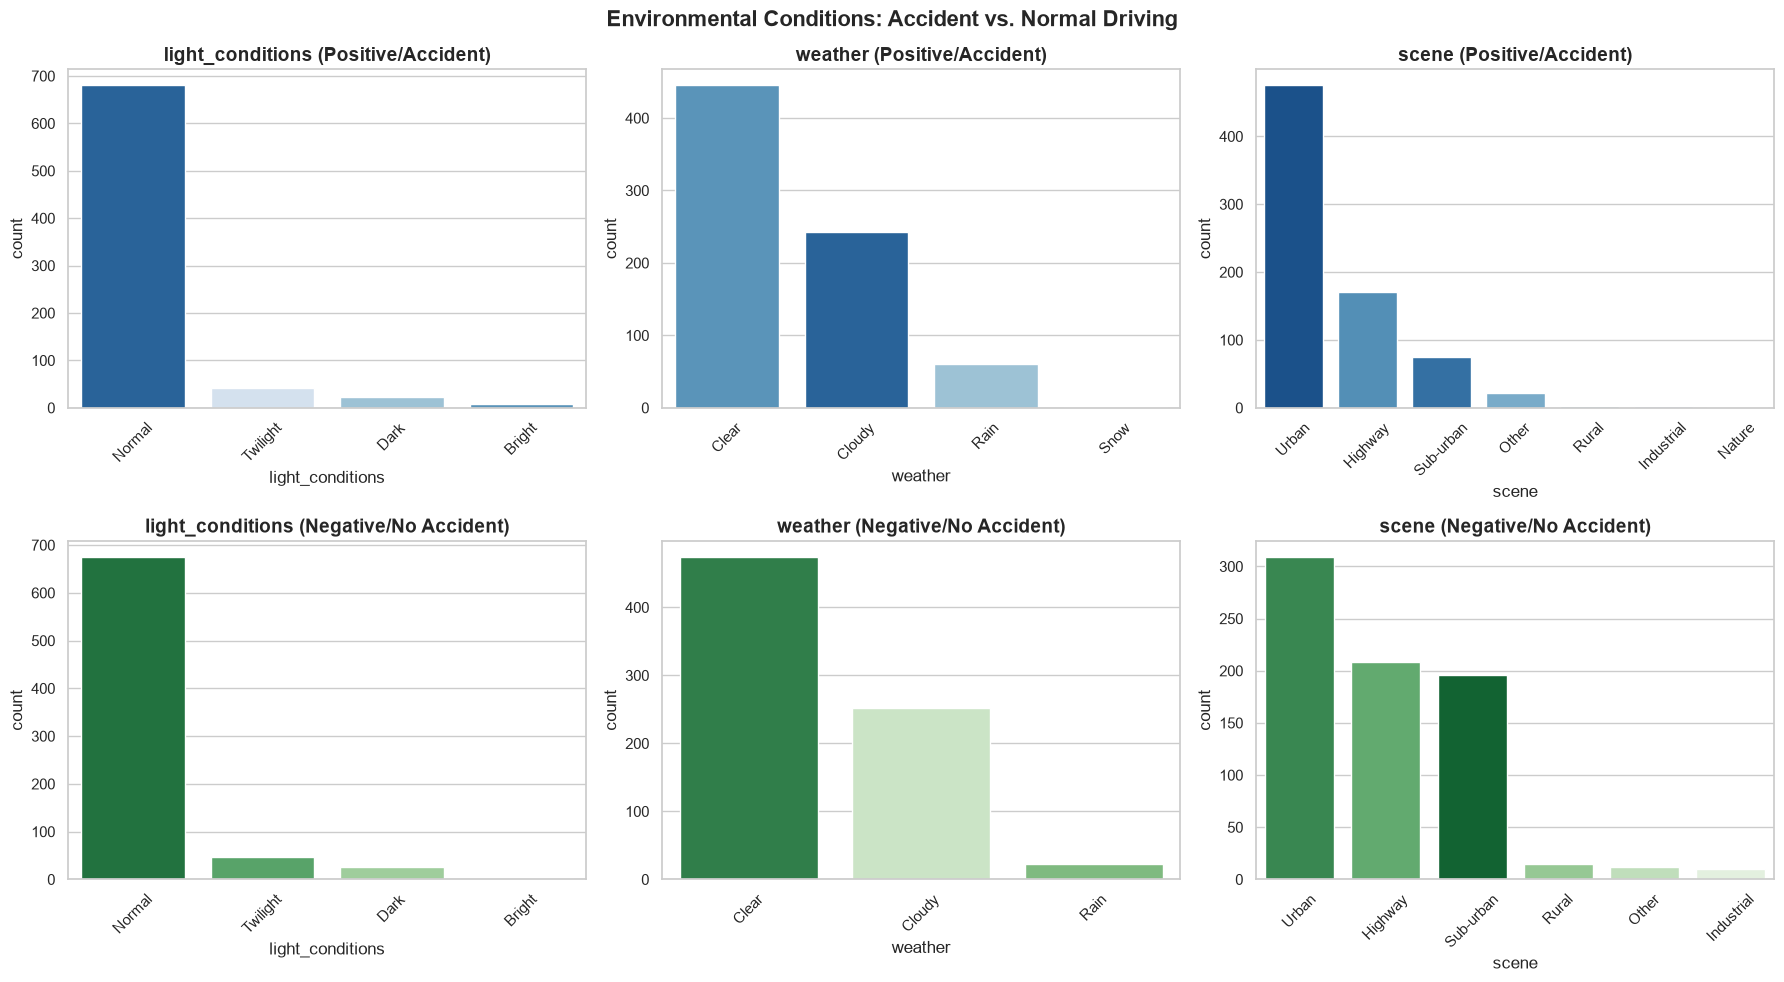


========== TIME OF EVENT DISTRIBUTION ==========


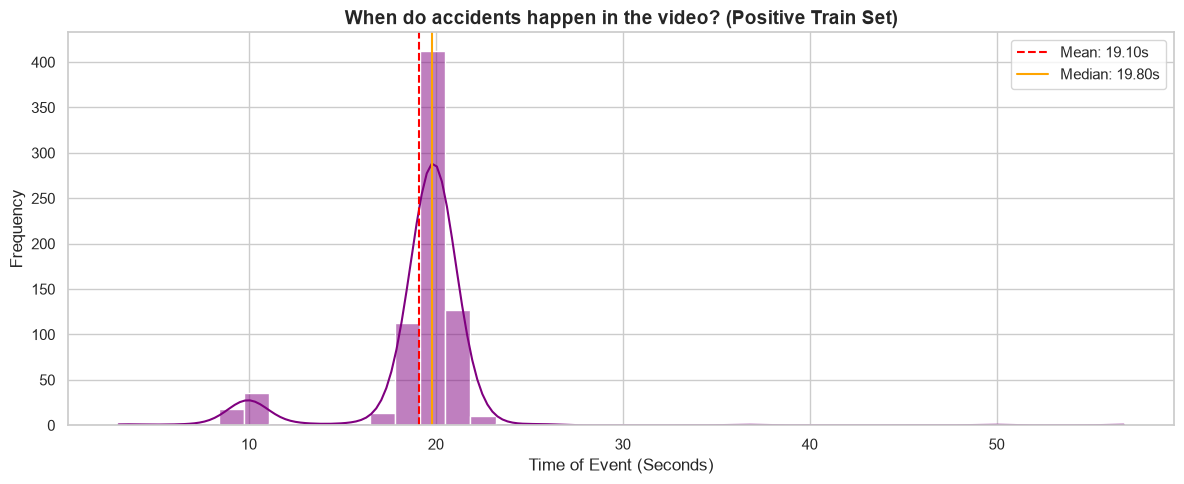

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set a beautiful, professional style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14, 'axes.titleweight': 'bold'})

# ==========================================
# 1. CLASS BALANCE ACROSS SPLITS
# ==========================================
print("========== CLASS BALANCE ACROSS SPLITS ==========")
splits = ['Train', 'Validation', 'Test']
counts_0 = [sum(final_train['label']==0), sum(final_val['label']==0), sum(final_test['label']==0)]
counts_1 = [sum(final_train['label']==1), sum(final_val['label']==1), sum(final_test['label']==1)]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(splits))
width = 0.35

rects1 = ax.bar(x - width/2, counts_0, width, label='No Accident (0)', color='#4C72B0')
rects2 = ax.bar(x + width/2, counts_1, width, label='Accident (1)', color='#C44E52')

ax.set_ylabel('Number of Videos')
ax.set_title('Class Balance Across Train, Validation, and Test Sets')
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.legend()
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)
plt.tight_layout()
plt.show()

# ==========================================
# 2. METADATA LEAKAGE AUDIT (Visualized)
# ==========================================
print("\n========== METADATA LEAKAGE AUDIT ==========")
df_pos = prepared_metadata['train/positive/metadata.csv']
df_neg = prepared_metadata['train/negative/metadata.csv']
df_all_train = pd.concat([df_pos, df_neg])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    leakage_check = df_all_train.groupby(col)['label'].mean().sort_values(ascending=False)
    
    # FIX 1: Added hue and legend=False to fix the Seaborn FutureWarning
    sns.barplot(x=leakage_check.values, y=leakage_check.index, ax=axes[i], 
                hue=leakage_check.index, palette="Reds_r", legend=False)
    
    axes[i].axvline(0.5, color='black', linestyle='--', alpha=0.7)
    axes[i].set_title(f'Accident Probability by {col.replace("_", " ").title()}')
    axes[i].set_xlabel('Probability of Accident (Label=1)')
    axes[i].set_xlim(0, 1.1)
    
    # FIX 2: Replaced the ⚠️ emoji with "(!)" so the Windows font can display it
    for j, v in enumerate(leakage_check.values):
        if v > 0.8 or v < 0.2:
            axes[i].text(v + 0.02, j, f"{v:.2f} (!)", va='center', fontweight='bold', color='darkred')

plt.suptitle('Metadata Leakage Audit: Are we giving the model shortcuts?', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 3. POSITIVE VS NEGATIVE DISTRIBUTIONS
# ==========================================
print("\n========== POSITIVE VS NEGATIVE ENVIRONMENT DISTRIBUTIONS ==========")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    # Positive Plot (FIXED)
    sns.countplot(data=df_pos, x=col, ax=axes[0, i], order=df_pos[col].value_counts().index, 
                  hue=col, palette="Blues_r", legend=False)
    axes[0, i].set_title(f'{col} (Positive/Accident)')
    axes[0, i].tick_params(axis='x', rotation=45)
    
    # Negative Plot (FIXED)
    sns.countplot(data=df_neg, x=col, ax=axes[1, i], order=df_neg[col].value_counts().index, 
                  hue=col, palette="Greens_r", legend=False)
    axes[1, i].set_title(f'{col} (Negative/No Accident)')
    axes[1, i].tick_params(axis='x', rotation=45)
plt.suptitle('Environmental Conditions: Accident vs. Normal Driving', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 4. TIME OF EVENT DISTRIBUTION
# ==========================================
print("\n========== TIME OF EVENT DISTRIBUTION ==========")
plt.figure(figsize=(12, 5))
sns.histplot(data=metadata_dfs['train/positive/metadata.csv'], x='time_of_event', bins=40, kde=True, color='purple')
mean_time = metadata_dfs['train/positive/metadata.csv']['time_of_event'].mean()
median_time = metadata_dfs['train/positive/metadata.csv']['time_of_event'].median()
plt.axvline(mean_time, color='red', linestyle='--', label=f'Mean: {mean_time:.2f}s')
plt.axvline(median_time, color='orange', linestyle='-', label=f'Median: {median_time:.2f}s')

plt.title('When do accidents happen in the video? (Positive Train Set)')
plt.xlabel('Time of Event (Seconds)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

برای جلوگیری از **Data Leakage**، ستون‌های `time_of_event`، `time_of_alert` و `time_to_accident` نباید وارد مدل شوند، چون اطلاعات مربوط به وقوع حادثه را آشکار می‌کنند یا برای آموزش مفید نیستند.

همچنین ستون‌های `weather`، `scene` و `light_conditions` فقط برای تحلیل داده‌ها و نمونه‌گیری استفاده می‌شوند و `file_name` و `video_path` صرفاً برای شناسایی و بارگذاری ویدئوها هستند.

**ورودی مدل فقط فریم‌های ویدئو است** و ستون `label` صرفاً به‌عنوان پاسخ واقعی برای آموزش و ارزیابی استفاده می‌شود.

Uniform Temporal Sampling

In [18]:
import cv2
import numpy as np

FRAME_INTERVAL = 0.1
IMAGE_SIZE = (224, 224)


def extract_frames(video_path):
    cap = cv2.VideoCapture(str(video_path))

    try:
        if not cap.isOpened():
            raise ValueError(f"Cannot open video: {video_path}")

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)

        if (
            not np.isfinite(fps)
            or fps <= 0
            or not np.isfinite(frame_count)
            or frame_count < 1
        ):
            raise ValueError(f"Invalid video metadata: {video_path}")

        total_frames = int(frame_count)
        duration = total_frames / fps

        # Sample the entire video at 0, 0.1, 0.2, 0.3, ... seconds (10 fps).
        target_times = np.arange(0, duration, FRAME_INTERVAL)

        # Select the nearest available video frame.
        indices = np.rint(target_times * fps).astype(np.int64)
        indices = np.unique(indices[indices < total_frames])

        if len(indices) == 0:
            raise ValueError(f"No frames available: {video_path}")

        wanted = set(indices.tolist())
        last = int(indices[-1])
        frames = []
        pos = 0
        while pos <= last:
            ok = cap.grab()
            if not ok:
                raise ValueError(f"Cannot read frame {pos}: {video_path}")
            if pos in wanted:
                ok, frame = cap.retrieve()
                if not ok:
                    raise ValueError(f"Cannot read frame {pos}: {video_path}")
                frame = cv2.resize(frame, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
                frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            pos += 1

        timestamps = indices / fps

        return np.stack(frames), timestamps, indices

    finally:
        cap.release()

آزمایش و نمایش ۶۴ فریم

Video: 01034.mp4
Frames shape: (393, 224, 224, 3)
Extracted frames: 393
Sampling interval (seconds): 0.1
First timestamp: 0.0
Last timestamp: 39.2


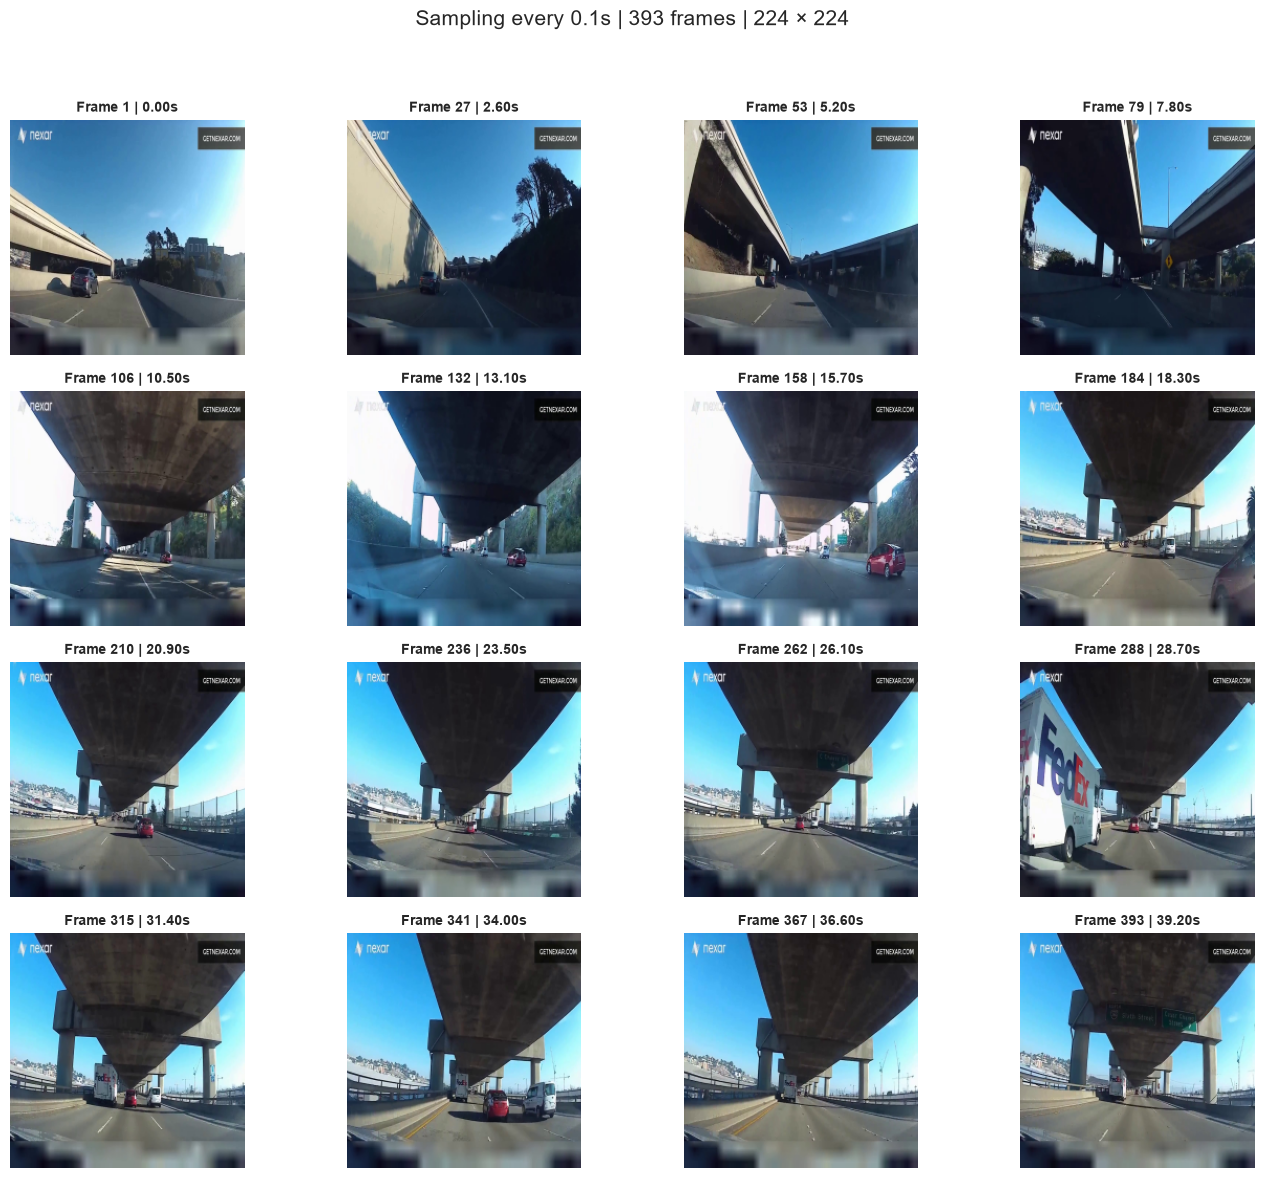

In [19]:
from huggingface_hub import hf_hub_download
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ID = "nexar-ai/nexar_collision_prediction"

# خواندن متادیتای ترین
train_df = pd.read_csv("data/processed_v2/train_360.csv")

# انتخاب یک ویدئوی مثبت برای بررسی
sample = train_df[train_df["label"] == 1].iloc[0]

# استفاده از ویدئوی کش‌شده یا دانلود آن
video_path = hf_hub_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    filename=sample["video_path"],
    local_dir="data/video_cache"
)

# استخراج با تابع جدید سلول ۱۷
frames, timestamps, indices = extract_frames(video_path)

print("Video:", sample["file_name"])
print("Frames shape:", frames.shape)
print("Extracted frames:", len(frames))
print("Sampling interval (seconds):", FRAME_INTERVAL)
print("First timestamp:", timestamps[0])
print("Last timestamp:", timestamps[-1])

assert frames.shape[1:] == (224, 224, 3)

# نمایش حداکثر ۱۶ فریم از سراسر ویدئو
shown = np.linspace(
    0, len(frames) - 1, min(16, len(frames))
).round().astype(int)

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, i in zip(axes.flat, shown):
    ax.imshow(frames[i])
    ax.set_title(
        f"Frame {i + 1} | {timestamps[i]:.2f}s",
        fontsize=10
    )

fig.suptitle(
    f"Sampling every {FRAME_INTERVAL}s | "
    f"{len(frames)} frames | 224 × 224",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

استخراج برای تمام 300 ویدئوی انتخابی

In [20]:
from pathlib import Path
from huggingface_hub import hf_hub_download
import numpy as np
import pandas as pd

REPO_ID = "nexar-ai/nexar_collision_prediction"

root = Path("data/frames_10fps_300")
cache_dir = Path("data/video_cache")
root.mkdir(parents=True, exist_ok=True)

df = pd.concat(
    [
        pd.read_csv("data/processed_v3/train_240.csv"),
        pd.read_csv("data/processed_v3/val_60.csv"),
    ],
    ignore_index=True
)
assert df["video_path"].is_unique

completed, skipped, failed = 0, 0, []

for i, (_, row) in enumerate(df.iterrows(), start=1):
    output = root / Path(row["video_path"]).with_suffix(".npz")

    if output.exists():
        skipped += 1
        continue

    try:
        video = cache_dir / row["video_path"]
        if not video.exists():
            video = Path(
                hf_hub_download(
                    repo_id=REPO_ID,
                    repo_type="dataset",
                    filename=row["video_path"],
                    local_dir=cache_dir
                )
            )

        frames, timestamps, indices = extract_frames(video)

        output.parent.mkdir(parents=True, exist_ok=True)
        temporary_output = output.with_suffix(".tmp.npz")

        np.savez_compressed(
            temporary_output,
            frames=frames,
            timestamps=timestamps,
            indices=indices,
            label=int(row["label"]),
            frame_interval=FRAME_INTERVAL
        )
        temporary_output.replace(output)

        completed += 1
        print(f"[{i}/{len(df)}] {row['file_name']} | {len(frames)} frames")

    except Exception as e:
        failed.append((row["video_path"], str(e)))
        print(f"[{i}/{len(df)}] FAILED: {row['video_path']} | {e}")

expected = [root / Path(p).with_suffix(".npz") for p in df["video_path"]]

print("\n========== RESULTS ==========")
print("Completed in this run:", completed)
print("Previously completed:", skipped)
print("Failed in this run:", len(failed))
print(f"Ready: {sum(p.exists() for p in expected)}/{len(df)}")
print("Saved in:", root.resolve())

if failed:
    print("\nFailed videos:")
    for video_path, error in failed:
        print(video_path, "|", error)


[1/300] 01720.mp4 | 403 frames
[2/300] 01592.mp4 | 401 frames
[3/300] 01566.mp4 | 400 frames
[4/300] 01004.mp4 | 399 frames
[5/300] 00869.mp4 | 401 frames
[6/300] 00355.mp4 | 395 frames
[7/300] 01153.mp4 | 402 frames
[8/300] 00192.mp4 | 403 frames
[9/300] 01663.mp4 | 406 frames
[10/300] 00626.mp4 | 403 frames
[11/300] 01461.mp4 | 409 frames
[12/300] 01090.mp4 | 394 frames
[13/300] 01942.mp4 | 403 frames
[14/300] 00988.mp4 | 180 frames
[15/300] 01491.mp4 | 407 frames
[16/300] 00411.mp4 | 409 frames
[17/300] 00173.mp4 | 180 frames
[18/300] 01306.mp4 | 406 frames
[19/300] 01600.mp4 | 401 frames
[20/300] 00298.mp4 | 402 frames
[21/300] 01783.mp4 | 401 frames
[22/300] 01508.mp4 | 415 frames
[23/300] 01214.mp4 | 401 frames
[24/300] 00130.mp4 | 401 frames
[25/300] 01446.mp4 | 394 frames
[26/300] 00117.mp4 | 394 frames
[27/300] 00473.mp4 | 427 frames
[28/300] 02059.mp4 | 395 frames
[29/300] 00873.mp4 | 408 frames
[30/300] 00625.mp4 | 408 frames
[31/300] 00792.mp4 | 401 frames
[32/300] 00885.mp

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd

root = Path("data/frames_10fps_300")

train = pd.read_csv("data/processed_v3/train_240.csv")
val = pd.read_csv("data/processed_v3/val_60.csv")
df = pd.concat([train, val], ignore_index=True)

assert len(train) == 240 and len(val) == 60
assert set(train["video_path"]).isdisjoint(set(val["video_path"]))

frame_counts = []
for _, row in df.iterrows():
    path = root / Path(row["video_path"]).with_suffix(".npz")
    assert path.exists(), f"Missing: {path}"

    with np.load(path, allow_pickle=False) as data:
        frames = data["frames"]
        timestamps = data["timestamps"]
        indices = data["indices"]

        assert frames.ndim == 4 and frames.shape[1:] == (224, 224, 3), path
        assert frames.dtype == np.uint8, path
        assert timestamps.shape == indices.shape == (len(frames),), path
        assert np.isfinite(timestamps).all(), path
        assert indices[0] == 0 and timestamps[0] == 0, path
        assert np.all(np.diff(indices) > 0), path
        assert np.all(np.diff(timestamps) > 0), path
        assert int(data["label"].item()) == int(row["label"]), path
        assert np.isclose(data["frame_interval"].item(), 0.1), path

        frame_counts.append(len(frames))

print("Verification passed!")
print(f"Train: {len(train)} | Validation: {len(val)}")
print(f"Frames per video: {min(frame_counts)} to {max(frame_counts)}")
print(f"Total frames: {sum(frame_counts)}")
print("Sampling: 10 frames per second, entire video, 224 × 224")


Verification passed!
Train: 240 | Validation: 60
Frames per video: 180 to 600
Total frames: 112900
Sampling: 10 frames per second, entire video, 224 × 224


نرمال سازی پیکسلها 

data agumentation 

In [22]:
import numpy as np
import torch
import pandas as pd
from pathlib import Path
from torch.utils.data import Dataset


def video_augmentation(frames, probability=0.5):
    if np.random.random() >= probability:
        return frames

    # Use the same adjustment for every frame of one video.
    brightness = np.random.uniform(0.9, 1.1)
    contrast = np.random.uniform(0.9, 1.1)

    frames = (frames - 0.5) * contrast + 0.5
    frames = frames * brightness
    frames = np.clip(frames, 0.0, 1.0)

    return frames.astype(np.float32)


class AccidentVideoDataset(Dataset):

    def __init__(self, csv_path, frame_dir, augment=False):
        self.df = pd.read_csv(csv_path)
        self.frame_dir = Path(frame_dir)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        frame_path = (
            self.frame_dir
            / Path(row["video_path"]).with_suffix(".npz")
        )

        with np.load(frame_path, allow_pickle=False) as data:
            frames = data["frames"]

        frames = frames.astype(np.float32) / 255.0

        if self.augment:
            frames = video_augmentation(frames)

        # [T, H, W, C] -> [T, C, H, W]
        frames = torch.from_numpy(
            np.ascontiguousarray(frames)
        ).permute(0, 3, 1, 2).contiguous()

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return frames, label


FRAME_DIR = "data/frames_10fps_300"

train_dataset = AccidentVideoDataset(
    "data/processed_v3/train_240.csv",
    FRAME_DIR,
    augment=True
)

val_dataset = AccidentVideoDataset(
    "data/processed_v3/val_60.csv",
    FRAME_DIR,
    augment=False
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train Augmentation: Enabled")
print("Validation Augmentation: Disabled")


Train samples: 240
Validation samples: 60
Train Augmentation: Enabled
Validation Augmentation: Disabled


بررسی مجدد توازن 


,No Accident (0),Accident (1)
Train,180,180
Validation,45,45



Class Balance (%):


,No Accident (0),Accident (1)
Train,50.0,50.0
Validation,50.0,50.0


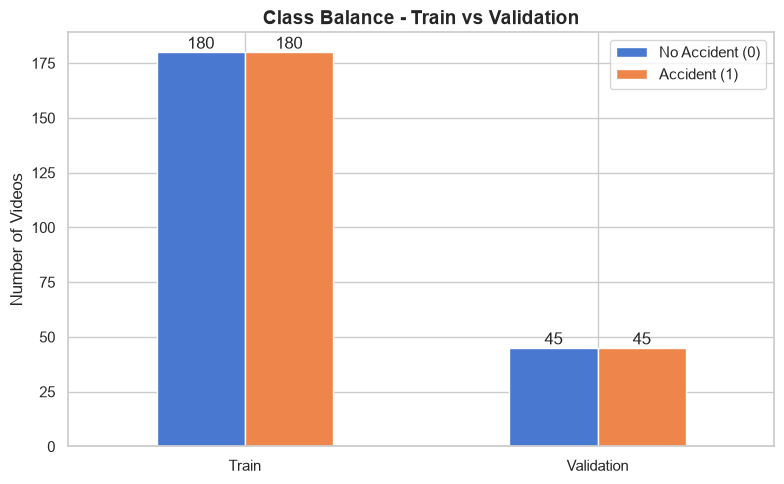

✅ Classes are balanced. No class weighting needed.


In [23]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("data/processed_v2/train_360.csv")
val = pd.read_csv("data/processed_v2/val_90.csv")

# Class Distribution
counts = pd.DataFrame({
    "Train": train["label"].value_counts(),
    "Validation": val["label"].value_counts()
}).T.reindex(columns=[0, 1], fill_value=0)

counts.columns = ["No Accident (0)", "Accident (1)"]

# Display counts and percentages
display(counts)
print("\nClass Balance (%):")
display(counts.div(counts.sum(axis=1), axis=0) * 100)

# Plot
ax = counts.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Class Balance - Train vs Validation")
ax.set_ylabel("Number of Videos")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.tight_layout()
plt.show()

# Final Check
if (counts.iloc[:, 0] == counts.iloc[:, 1]).all():
    print("✅ Classes are balanced. No class weighting needed.")
else:
    print("⚠️ Class imbalance detected. Review class ratios.")

بررسی نهایی

In [ ]:
# from pathlib import Path
# import numpy as np
# import pandas as pd

# train = pd.read_csv("data/processed_v2/train_360.csv")
# val = pd.read_csv("data/processed_v2/val_90.csv")

# root = Path("data/sampled_frames_fullvideo_2s_224")
# df = pd.concat([train, val], ignore_index=True)

# assert len(train) == 360
# assert len(val) == 90
# assert df["video_path"].is_unique

# assert set(train["video_path"]).isdisjoint(
#     set(val["video_path"])
# ), "Train and validation overlap!"

# frame_counts = []

# for _, row in df.iterrows():
#     path = root / Path(row["video_path"]).with_suffix(".npz")

#     assert path.exists(), f"Missing file: {path}"

#     with np.load(path, allow_pickle=False) as data:
#         frames = data["frames"]
#         timestamps = data["timestamps"]
#         indices = data["indices"]

#         assert frames.ndim == 4, f"Invalid dimensions: {path}"
#         assert len(frames) > 0, f"Empty video: {path}"
#         assert frames.shape[1:] == (224, 224, 3), \
#             f"Invalid image size: {path}"
#         assert frames.dtype == np.uint8, \
#             f"Invalid pixel dtype: {path}"

#         assert int(data["label"].item()) == int(row["label"]), \
#             f"Label mismatch: {path}"

#         assert np.isclose(data["frame_interval"].item(), 2.0), \
#             f"Invalid sampling interval: {path}"

#         n = len(frames)

#         assert timestamps.shape == indices.shape == (n,), \
#             f"Array lengths do not match: {path}"

#         assert np.isfinite(timestamps).all(), \
#             f"Invalid timestamps: {path}"

#         assert indices[0] == 0 and timestamps[0] == 0, \
#             f"Sampling does not start at zero: {path}"

#         assert np.all(np.diff(indices) > 0), \
#             f"Invalid frame order: {path}"

#         assert np.all(np.diff(timestamps) > 0), \
#             f"Invalid timestamp order: {path}"

#         if n > 1:
#             fps = indices[-1] / timestamps[-1]
#             target_times = np.arange(n) * 2.0

#             # Allow rounding to the nearest video frame.
#             assert np.all(
#                 np.abs(timestamps - target_times)
#                 <= 0.5 / fps + 1e-6
#             ), f"Sampling interval mismatch: {path}"

#         frame_counts.append(n)

# print("Preprocessing validation passed!")
# print(f"Train: {len(train)} | Validation: {len(val)}")
# print(
#     f"Frames per video: "
#     f"{min(frame_counts)} to {max(frame_counts)}"
# )
# print("Frame size: 224 × 224")
# print("Sampling interval: 1/3 seconds")
# print("Sampling scope: entire video")